# Azure OpenAI streaming latency

Measure client-observed streaming latency with Microsoft Entra ID and display every captured metric. The notebook supports both the Chat Completions path from support case `2607310040006239` and the current Microsoft Foundry Responses streaming example.

Request metrics contain timings, counts, usage, and IDs. A separate raw SSE JSONL log stores response payloads, including generated text, for every measured run and any failed warmup. Section 5 displays the full decoded response, including chunk text, by default. Failed requests immediately print their raw HTTP error body or SSE stream received so far. Request headers and credentials are not logged.

## 1. Configuration

The notebook finds the nearest `.env`, using the same required variables as `../web-search/.env`. Install dependencies once with `python -m pip install openai azure-identity python-dotenv pandas httpx matplotlib`.

In [ ]:
from __future__ import annotations

import hashlib
import json
import os
import time
import uuid
from datetime import datetime, timezone
from itertools import pairwise
from pathlib import Path
from urllib.parse import urlsplit

import httpx
import matplotlib.pyplot as plt
import pandas as pd
from azure.identity import DefaultAzureCredential, get_bearer_token_provider
from dotenv import load_dotenv
from openai import APIStatusError, OpenAI

try:
    from IPython.display import display
except ImportError:

    def display(value) -> None:
        print(value.to_string() if hasattr(value, "to_string") else value)


def find_project_dir() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / ".env").exists():
            return candidate
    raise FileNotFoundError("No .env found in the current directory or its parents.")


def required_env(name: str) -> str:
    value = os.getenv(name, "").strip()
    if not value:
        raise ValueError(f"Set {name} in .env.")
    return value


def normalize_base_url(endpoint: str) -> str:
    endpoint = endpoint.rstrip("/")
    if not endpoint.endswith("/openai/v1"):
        endpoint += "/openai/v1"
    return endpoint + "/"


PROJECT_DIR = find_project_dir()
load_dotenv(PROJECT_DIR / ".env", override=True)

BASE_URL = normalize_base_url(required_env("AZURE_OPENAI_ENDPOINT"))
DEPLOYMENT = required_env("AZURE_OPENAI_DEPLOYMENT")
TENANT_ID = required_env("AZURE_TENANT_ID")
TOKEN_SCOPE = os.getenv("AZURE_OPENAI_TOKEN_SCOPE", "https://ai.azure.com/.default")
API = os.getenv("AZURE_OPENAI_STREAMING_API", "chat-completions")
LABEL = os.getenv("STREAMING_TEST_LABEL", "direct")
RUNS = int(os.getenv("STREAMING_RUNS", "5"))
WARMUP_RUNS = int(os.getenv("STREAMING_WARMUP_RUNS", "1"))
DELAY_SECONDS = float(os.getenv("STREAMING_DELAY_SECONDS", "1"))
TIMEOUT_SECONDS = float(os.getenv("STREAMING_TIMEOUT_SECONDS", "120"))
MAX_OUTPUT_TOKENS = int(os.getenv("AZURE_OPENAI_MAX_COMPLETION_TOKENS", "25600"))
REASONING_EFFORT = os.getenv("AZURE_OPENAI_REASONING_EFFORT") or None
# Display limit only: 0 shows all SSE lines; a positive value shows a prefix.
RAW_EVENT_LIMIT = int(os.getenv("STREAMING_RAW_EVENT_LIMIT", "0"))
PATH_NAME = os.getenv("STREAMING_PATH", LABEL).upper()
TIER = os.getenv("STREAMING_TIER", "dev")
SERVING = os.getenv("STREAMING_SERVING", "False")
WORKSPACE = os.getenv("STREAMING_WORKSPACE", "not set")
API_VERSION = os.getenv("AZURE_OPENAI_API_VERSION", "v1")

PROMPT = f"""
    {time.strftime('%Y-%m-%d %H:%M:%S', time.localtime())} 
    "STREAMING_PROMPT "
    c3c273be-9ad9-4132-acbf-adb9ad1aa407. You are an expert in summarizing client reports for bankers and advisors. Generate a client summary using the exact section structure below.
General Instructions:
1. Use only provided input data. Do not infer, assume, or invent.
2. Keep wording concise, factual, and professional.
3. If an entire section input is empty or missing, output one bullet: "No data available" only where instructed. Otherwise, skip only null or empty fields.
4. Inputs are JSON. Use only fields explicitly requested for each section.
5. Use "Client", not "Customer". Use neutral pronouns (they/their).
6. Mask sensitive numbers (SSNs, card numbers, and any 16-digit number). Do not mask phone numbers or emails.
7. Clean extracted values by trimming whitespace and stray symbols.
8. Use Markdown bullets exactly as specified.
9. Output valid Markdown only.
10. Use the exact headers and subheaders below. Do not add sections or horizontal rules.
11. Heading levels are mandatory:
- Main headers ("Highlights", "Call Summaries", and "Opportunities") use ##.
- Subheaders ("Discover Needs", "Meetings", "Open Opportunities", and "Closed Opportunities") use ####.
- Sub-subheaders ("Upcoming Meetings" and "Past Meetings") use ######.
12. Each record's `RecordUrl` already contains a fully formatted Markdown hyperlink. Use it verbatim wherever specified.

## Highlights

Input fields: `clientRecord`, `relatedBusinesses`, `relatedContacts`, `updatedDiscoverNeeds`, `clientPastMeetings`, and `clientFutureMeetings`.

Provide up to five bullets total, with no subheader:
- Up to three bullets containing key profile details from `clientRecord` only, including name, age, client type, client since date, last activity date, assigned banker, branch, occupation, and family details when present.
- Up to one bullet containing financial goals or other key messages from `clientRecord`. Skip it when no data is available. Do not use `updatedDiscoverNeeds` here.
- If `IsPersonAccount` is true, output: `Related Business Names: <list>`. Build `<list>` by joining the `RecordUrl` values from `relatedBusinesses` with commas. If the list is null or empty, use `No data available`.
- If `IsPersonAccount` is false, output: `Related Contact Names: <list>`. Build `<list>` by joining the `RecordUrl` values from `relatedContacts` with commas. If the list is null or empty, use `No data available`.

Notes:
- Only the related-entities bullet may contain hyperlinks.
- Preferred language defaults to English. Mention `languagePreferenceExpanded` only when it is non-null and not English.

#### Discover Needs
Summarize `updatedDiscoverNeeds` as plain-text bullets.
- Skip null or empty descriptions.
- Summarize long descriptions to their key points.
- If the entire list is empty, output `- No data available`.

#### Meetings

###### Upcoming Meetings
Use `clientFutureMeetings` in input order.
- Format each bullet as `RecordUrl: subject and description`.
- Use `RecordUrl` verbatim in place of the plain date and time.
- Skip null or empty descriptions and summarize long descriptions.
- If the list is null or empty, output `- No data available`.

###### Past Meetings
Use `clientPastMeetings` as provided.

Always print this non-bullet line first:
Here are the most recent meetings in the past three years (up to 5):

- Format each meeting as `RecordUrl: subject and description`.
- Use `RecordUrl` verbatim in place of the plain date.
- Skip null or empty descriptions and summarize long descriptions.
- If the list is null or empty, print the line above followed by `- No data available`.

Here is the input of "ClientRecord":

{{  "clientRecord": {{
    "Name": "CORWITT LLC",
    "languagePreferenceExpanded": "N/A",
    "IsPersonAccount": false,
    "hhLastActivityDate": "Jul 21, 2026",
    "Description": null,
    "customerType": "Business Premier",
    "customerSinceDate": "Dec 28, 2007",
    "branch": null,
    "assignedBanker": null
  }}
}}

Provide a 1200 word response, insert the word banana into the first paragraph of the response.
"""


OUTPUT_PATH = PROJECT_DIR / "results" / "notebook-streaming-latency.jsonl"
RAW_SSE_OUTPUT_PATH = PROJECT_DIR / "results" / "notebook-streaming-raw-sse.jsonl"

if API not in {"chat-completions", "responses"}:
    raise ValueError("API must be 'chat-completions' or 'responses'.")
if MAX_OUTPUT_TOKENS <= 0:
    raise ValueError("MAX_OUTPUT_TOKENS must be greater than zero.")
if RAW_EVENT_LIMIT < 0:
    raise ValueError("RAW_EVENT_LIMIT cannot be negative.")

## 2. Entra-authenticated client

The SDK receives a renewable bearer-token provider. Retries are disabled so each row represents exactly one HTTP request.

In [47]:
credential = DefaultAzureCredential()
token_provider = get_bearer_token_provider(credential, TOKEN_SCOPE)
client = OpenAI(
    base_url=BASE_URL,
    api_key=token_provider,
    max_retries=0,
    timeout=httpx.Timeout(TIMEOUT_SECONDS, connect=min(TIMEOUT_SECONDS, 30)),
)


def mask_identifier(value: str) -> str:
    return f"{value[:4]}...{value[-4:]}" if len(value) > 8 else "***"


gateway_description = "no gateway" if PATH_NAME == "DIRECT" else "gateway"
print("=== AUTH DETAILS ===")
print(f"credential : {type(credential).__name__}")
print(f"tenant     : {mask_identifier(TENANT_ID)}")
print(f"scope      : {TOKEN_SCOPE}")
print("token      : acquired on demand; value not displayed")
print("=== END AUTH DETAILS ===")
print()
print(
    f"path      : {PATH_NAME} ({gateway_description}, tier={TIER}, serving={SERVING})"
)
print(f"endpoint  : {BASE_URL}")
print(f"workspace : {WORKSPACE}")
print(f"model     : {DEPLOYMENT}    api: {API_VERSION}")

=== AUTH DETAILS ===
credential : DefaultAzureCredential
tenant     : 16b3...b6d3
scope      : https://ai.azure.com/.default
token      : acquired on demand; value not displayed
=== END AUTH DETAILS ===

path      : DIRECT (no gateway, tier=dev, serving=False)
endpoint  : https://jacwang-foundryonly.cognitiveservices.azure.com/openai/v1/
workspace : not set
model     : gpt-5-mini    api: v1


## 3. Measure the raw SSE stream

Here, **raw response** means the HTTP metadata plus the SSE lines returned by `response.iter_lines()` after the SDK has decoded the transport. The log preserves line contents and blank event separators; original line-ending bytes are not available through this interface. It is not a packet capture or the original compressed TCP bytes.

A streaming response is not one JSON document. It is a sequence of Server-Sent Event lines:

```text
HTTP/1.1 200
content-type: text/event-stream
apim-request-id: <request-id>

data: {"choices":[{"delta":{"role":"assistant"}}]}
data: {"choices":[{"delta":{"content":"1"}}]}
data: {"choices":[],"usage":{...}}
data: [DONE]
```

For Chat Completions, visible TTFT starts at the first non-empty `choices[0].delta.content`; a preceding role-only delta is an SSE event but not visible content. For Responses, visible TTFT starts at the first `response.output_text.delta` event with a non-empty `delta`.

> **Measurement boundary:** Azure does not include a per-token server-generation timestamp in these events. Therefore the client cannot calculate `token generated → SSE received`. The notebook measures when each SSE/content chunk is received and the gap since the previous received SSE. A content delta can contain zero, one, or multiple tokens. Chat Completions may include a `created` field, but it is coarse completion/chunk metadata repeated across events—not a per-token generation timestamp.

In [48]:
CORRELATION_HEADERS = (
    "apim-request-id",
    "request-id",
    "x-request-id",
    "x-ms-request-id",
    "x-ms-client-request-id",
    "x-ms-region",
    "openai-processing-ms",
    "x-envoy-upstream-service-time",
    "server-timing",
    "traceparent",
    "x-correlation-id",
)
CHECKPOINT_FIELDS = (
    "pre_inference_ms",
    "engine_ttft_ms",
    "service_ttft_ms",
    "user_visible_ttft_ms",
    "engine_tbt_ms",
    "engine_ttlt_ms",
    "service_ttlt_ms",
)


def ms(later_ns: int | None, earlier_ns: int | None) -> float | None:
    if later_ns is None or earlier_ns is None:
        return None
    return round((later_ns - earlier_ns) / 1_000_000, 3)


def flatten(result: dict, prefix: str, value) -> None:
    if isinstance(value, dict):
        for key, child in value.items():
            flatten(result, f"{prefix}_{key}", child)
    elif isinstance(value, (str, int, float, bool)) or value is None:
        result[prefix] = value


def extract_latency_checkpoint(payload: dict) -> dict:
    checkpoint = {}
    containers = [payload, payload.get("response")]
    for container in containers:
        if not isinstance(container, dict):
            continue
        for name in ("serving_latency_checkpoint", "latency_checkpoint"):
            value = container.get(name)
            if isinstance(value, dict):
                checkpoint.update(value)
        for field in CHECKPOINT_FIELDS:
            if field in container:
                checkpoint[field] = container[field]
    return checkpoint


def print_raw_response(raw_response: dict, *, line_limit: int = 0) -> None:
    """Display decoded response content without reserializing its JSON payloads."""
    status = raw_response.get("status_code")
    if status is None:
        print("No HTTP response headers received.")
    else:
        print(f"{raw_response['http_version']} {status}")
        for key, value in raw_response["headers"].items():
            print(f"{key}: {value}")
        print()
    if raw_response.get("raw_body") is not None:
        print(raw_response["raw_body"])
    else:
        lines = raw_response["sse_lines"]
        shown = lines[:line_limit] if line_limit else lines
        for line in shown:
            print(line)
        if len(shown) < len(lines):
            print(f"... showing {len(shown)} of {len(lines)} lines; full stream is in the log")


def measure_stream(run: int, *, warmup: bool = False) -> tuple[dict, dict, list[dict]]:
    client_request_id = str(uuid.uuid4())
    started_utc = datetime.now(timezone.utc).isoformat()
    correlation_headers = {
        "x-ms-client-request-id": client_request_id,
        "x-client-request-id": client_request_id,
    }

    if API == "responses":
        request = {
            "model": DEPLOYMENT,
            "input": PROMPT,
            "stream": True,
            "max_output_tokens": MAX_OUTPUT_TOKENS,
            "extra_headers": correlation_headers,
        }
        if REASONING_EFFORT:
            request["reasoning"] = {"effort": REASONING_EFFORT}
        context = client.responses.with_streaming_response.create(**request)
    else:
        request = {
            "model": DEPLOYMENT,
            "messages": [{"role": "user", "content": PROMPT}],
            "stream": True,
            "stream_options": {"include_usage": True},
            "max_completion_tokens": MAX_OUTPUT_TOKENS,
            "extra_headers": correlation_headers,
        }
        if REASONING_EFFORT:
            request["reasoning_effort"] = REASONING_EFFORT
        context = client.chat.completions.with_streaming_response.create(**request)

    started_ns = time.perf_counter_ns()
    first_sse_ns = first_content_ns = last_content_ns = None
    previous_sse_ns = None
    event_timeline = []
    raw_sse_events = []
    raw_preview = {
        "http_version": None,
        "status_code": None,
        "headers": {},
        "sse_lines": [],
        "raw_body": None,
    }
    stream_error = None
    response_request_id = None
    event_count = content_event_count = output_chars = 0
    usage, model, finish_reason = {}, None, None
    latency_checkpoint = {}

    # Buffer decoded lines so file I/O does not inflate the measured stream time.
    try:
        with context as response:
            headers_ns = time.perf_counter_ns()
            response_headers = {
                key.lower(): value for key, value in response.headers.items()
            }
            response_request_id = response.request_id
            response_status = response.status_code
            raw_preview.update(
                http_version=response.http_version,
                status_code=response_status,
                headers={
                    key: value for key, value in response_headers.items()
                    if key != "set-cookie"
                },
            )

            for line_index, raw_line in enumerate(response.iter_lines(), start=1):
                arrived_ns = time.perf_counter_ns()
                sse_line = raw_line.decode() if isinstance(raw_line, bytes) else raw_line
                raw_sse_events.append(
                    {
                        "record_type": "sse_line",
                        "line_index": line_index,
                        "received_from_request_start_ms": ms(arrived_ns, started_ns),
                        "received_after_headers_ms": ms(arrived_ns, headers_ns),
                        "raw_line": sse_line,
                    }
                )
                line = sse_line.strip()
                if not line.startswith("data:"):
                    continue
                data = line[5:].lstrip()
                if data == "[DONE]":
                    break
                try:
                    payload = json.loads(data)
                except json.JSONDecodeError:
                    continue
                if not isinstance(payload, dict):
                    continue
                if "error" in payload:
                    raise RuntimeError(f"Stream error: {payload['error']!r}")
                if payload.get("type") == "error":
                    raise RuntimeError(f"Stream error: {payload!r}")
                if payload.get("type") == "response.failed":
                    raise RuntimeError(f"Response failed: {payload.get('response')!r}")
                latency_checkpoint.update(extract_latency_checkpoint(payload))

                first_sse_ns = first_sse_ns or arrived_ns
                event_count += 1
                content = None
                event_type = "chat.event"

                response_data = payload.get("response")
                if isinstance(response_data, dict):
                    model = response_data.get("model", model)
                    usage = response_data.get("usage") or usage
                    finish_reason = response_data.get("status", finish_reason)

                if API == "responses":
                    event_type = str(payload.get("type", "response.event"))
                    delta = payload.get("delta")
                    if (
                        payload.get("type") != "response.output_text.delta"
                        or not isinstance(delta, str)
                        or not delta
                    ):
                        content = None
                    else:
                        content = delta
                else:
                    model = payload.get("model", model)
                    usage = payload.get("usage") or usage
                    choices = payload.get("choices") or []
                    if choices:
                        choice = choices[0]
                        finish_reason = choice.get("finish_reason") or finish_reason
                        delta = choice.get("delta") or {}
                        content = delta.get("content")
                        if isinstance(content, str) and content:
                            event_type = "chat.content.delta"
                        else:
                            content = None
                            if delta.get("role"):
                                event_type = "chat.role.delta"
                            elif choice.get("finish_reason"):
                                event_type = "chat.finish"
                    elif usage:
                        event_type = "chat.usage"

                event_timeline.append(
                    {
                        "event_index": event_count,
                        "event_type": event_type,
                        "received_from_request_start_ms": ms(arrived_ns, started_ns),
                        "received_after_headers_ms": ms(arrived_ns, headers_ns),
                        "since_previous_sse_received_ms": ms(arrived_ns, previous_sse_ns),
                        "visible_content": content is not None,
                        "content_chunk_chars": len(content) if content else 0,
                    }
                )
                previous_sse_ns = arrived_ns
                if content is None:
                    continue

                first_content_ns = first_content_ns or arrived_ns
                last_content_ns = arrived_ns
                content_event_count += 1
                output_chars += len(content)
    except Exception as error:
        stream_error = error
        if isinstance(error, APIStatusError):
            # Non-2xx responses can contain JSON or a gateway's plain-text/HTML body.
            error_response = error.response
            response_request_id = error.request_id
            raw_preview.update(
                http_version=error_response.http_version,
                status_code=error_response.status_code,
                headers={
                    key.lower(): value for key, value in error_response.headers.items()
                    if key.lower() != "set-cookie"
                },
                raw_body=error_response.text,
            )
        raise
    finally:
        ended_ns = time.perf_counter_ns()
        raw_preview["sse_lines"] = [event["raw_line"] for event in raw_sse_events]
        if stream_error is not None:
            phase = "warmup" if warmup else "measured"
            print(f"\n=== RAW ERROR RESPONSE ({phase} run {run}; {client_request_id}) ===")
            print_raw_response(raw_preview)  # Errors always show all received lines.
            print(f"\nStream exception: {type(stream_error).__name__}: {stream_error}")
            print(f"Raw response log: {RAW_SSE_OUTPUT_PATH.resolve()}")

        # Keep failed warmups as well as measured runs for troubleshooting.
        save_raw = not warmup or stream_error is not None
        if save_raw and (raw_sse_events or raw_preview["raw_body"] is not None):
            RAW_SSE_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
            log_metadata = {
                "run": run,
                "warmup": warmup,
                "timestamp_utc": started_utc,
                "api": API,
                "client_request_id": client_request_id,
                "response_request_id": response_request_id,
                "status_code": raw_preview["status_code"],
                "http_version": raw_preview["http_version"],
            }
            with RAW_SSE_OUTPUT_PATH.open("a", encoding="utf-8") as raw_output:
                if raw_preview["raw_body"] is not None:
                    error_record = {
                        **log_metadata,
                        "record_type": "http_error",
                        "headers": raw_preview["headers"],
                        "raw_body": raw_preview["raw_body"],
                    }
                    raw_output.write(json.dumps(error_record, ensure_ascii=False) + "\n")
                for event in raw_sse_events:
                    raw_output.write(
                        json.dumps({**log_metadata, **event}, ensure_ascii=False) + "\n"
                    )

    result = {
        "run": run,
        "warmup": warmup,
        "timestamp_utc": started_utc,
        "api": API,
        "label": LABEL,
        "endpoint_host": urlsplit(BASE_URL).netloc,
        "deployment": DEPLOYMENT,
        "model": model,
        "client_request_id": client_request_id,
        "response_request_id": response_request_id,
        "response_status": response_status,
        "raw_sse_log_path": str(RAW_SSE_OUTPUT_PATH.resolve()) if not warmup else None,
        "finish_reason": finish_reason,
        "prompt_sha256": hashlib.sha256(PROMPT.encode()).hexdigest(),
        "prompt_chars": len(PROMPT),
        "max_output_tokens": MAX_OUTPUT_TOKENS,
        "reasoning_effort": REASONING_EFFORT,
        "response_headers_ms": ms(headers_ns, started_ns),
        "streaming_handshake_ms": ms(headers_ns, started_ns),
        "first_sse_received_ms": ms(first_sse_ns, started_ns),
        "ttft_ms": ms(first_content_ns, started_ns),
        "last_content_received_ms": ms(last_content_ns, started_ns),
        "stream_complete_ms": ms(ended_ns, started_ns),
        "total_duration_ns": ended_ns - started_ns,
        "headers_to_first_sse_received_ms": ms(first_sse_ns, headers_ns),
        "handshake_to_first_token_ms": ms(first_content_ns, headers_ns),
        "first_sse_to_first_content_ms": ms(first_content_ns, first_sse_ns),
        "sse_events": event_count,
        "content_events": content_event_count,
        "output_chars": output_chars,
    }
    for header in CORRELATION_HEADERS:
        result[f"header_{header}"] = response_headers.get(header)
    for field in CHECKPOINT_FIELDS:
        result[f"checkpoint_{field}"] = latency_checkpoint.get(field)
    flatten(result, "usage", usage)
    return result, raw_preview, event_timeline

## 4. Run and display request metrics

The cell prints an operations-friendly report for each measured request. Warmups are excluded from the saved results. Client-observed values are labeled separately from service checkpoints; a service checkpoint is shown only when the API or gateway actually returns it. Every measured result is appended to `results/notebook-streaming-latency.jsonl`. Raw SSE lines are automatically appended to `results/notebook-streaming-raw-sse.jsonl`, independently of the preview limit. Both paths are relative to the directory containing the loaded `.env`; the cell prints their absolute locations. Successful warmups are excluded from both files. Failed warmups are included in the raw log for troubleshooting. Any failed request prints its raw response immediately before the exception is re-raised.

In [49]:
def format_ms(value) -> str:
    return "N/A" if value is None else f"{float(value):.0f} ms"


def first_present(result: dict, *keys: str):
    for key in keys:
        if result.get(key) is not None:
            return result[key]
    return None


def format_token_count(value) -> str:
    return "N/A" if value is None else str(value)


def print_service_checkpoint(result: dict) -> None:
    print("serving latency_checkpoint:")
    for field in CHECKPOINT_FIELDS:
        value = result.get(f"checkpoint_{field}")
        source = "service"
        if value is None and field == "user_visible_ttft_ms":
            value = result.get("ttft_ms")
            source = "client-derived"
        if value is None:
            rendered = "N/A (not returned)"
        else:
            try:
                rendered = f"{float(value):g} ms [{source}]"
            except (TypeError, ValueError):
                rendered = f"{value} [{source}]"
        print(f"  {field:<24}: {rendered}")
    print(f"  {'total_duration_ns':<24}: {result['total_duration_ns']:,} ns [client]")


def print_result(result: dict, timeline: list[dict], run_number: int) -> None:
    content_arrivals = [
        event["received_from_request_start_ms"]
        for event in timeline
        if event["visible_content"]
    ]
    content_gaps = [later - earlier for earlier, later in pairwise(content_arrivals)]
    burst_count = sum(gap < 10 for gap in content_gaps)
    burst_percent = 100 * burst_count / len(content_gaps) if content_gaps else 0
    prompt_tokens = first_present(result, "usage_prompt_tokens", "usage_input_tokens")
    completion_tokens = first_present(
        result, "usage_completion_tokens", "usage_output_tokens"
    )
    suffix = f" [run {run_number}/{RUNS}]" if RUNS > 1 else ""

    print(f"=== RESULT ({PATH_NAME} / {TIER}){suffix} ===")
    print(f"first byte*       : {format_ms(result['streaming_handshake_ms'])}")
    print(f"client TTFT       : {format_ms(result['ttft_ms'])}")
    print(f"first byte -> token: {format_ms(result['handshake_to_first_token_ms'])}")
    print(f"client total      : {format_ms(result['stream_complete_ms'])}")
    print(f"content chunks    : {result['content_events']} / {result['sse_events']}")
    print(
        f"burst (<10 ms)     : {burst_count}/{len(content_gaps)} ({burst_percent:.0f}%)"
    )
    print(
        "tokens             : "
        f"prompt={format_token_count(prompt_tokens)} "
        f"completion={format_token_count(completion_tokens)}"
    )
    print()
    print(f"model      : {result.get('model') or DEPLOYMENT}")
    print(f"region     : {result.get('header_x-ms-region') or 'N/A'}")
    print(f"max_tokens : {MAX_OUTPUT_TOKENS}")
    print(f"prompt     : {len(PROMPT)} chars")
    print()
    print_service_checkpoint(result)
    print()
    print(
        "* Initial streaming handshake received: HTTP status and headers are available."
    )
    print("(generated content is saved separately in the raw SSE log)")


records, raw_previews, event_timelines = [], [], []
print(f"Raw response log (measured runs and errors): {RAW_SSE_OUTPUT_PATH.resolve()}")
print()
if WARMUP_RUNS:
    print("warming up (token + connection) ...")
    for warmup_index in range(WARMUP_RUNS):
        warmup_result, _, _ = measure_stream(warmup_index + 1, warmup=True)
        print(
            f"  warmup {warmup_index + 1}/{WARMUP_RUNS}: "
            f"{format_ms(warmup_result['stream_complete_ms'])}"
        )
        if DELAY_SECONDS:
            time.sleep(DELAY_SECONDS)
else:
    print("warming up ... skipped")

for measured_index in range(RUNS):
    result, raw_preview, event_timeline = measure_stream(measured_index + 1)
    records.append(result)
    raw_previews.append(raw_preview)
    event_timelines.append(event_timeline)
    print()
    print_result(result, event_timeline, measured_index + 1)
    if measured_index + 1 < RUNS and DELAY_SECONDS:
        time.sleep(DELAY_SECONDS)

results_df = pd.DataFrame(records)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with OUTPUT_PATH.open("a", encoding="utf-8") as output:
    for record in records:
        output.write(json.dumps(record, separators=(",", ":"), sort_keys=True) + "\n")
print(f"\nresults saved: {OUTPUT_PATH.resolve()}")
print(f"raw SSE log: {RAW_SSE_OUTPUT_PATH.resolve()}")

Raw response log (measured runs and errors): C:\repo\ai-foundry-craftkit\Model_Usecases\streaming-telemetry\results\notebook-streaming-raw-sse.jsonl

warming up (token + connection) ...
  warmup 1/1: 24140 ms

=== RESULT (DIRECT / dev) [run 1/5] ===
first byte*       : 21788 ms
client TTFT       : 21789 ms
first byte -> token: 1 ms
client total      : 23170 ms
content chunks    : 126 / 136
burst (<10 ms)     : 114/125 (91%)
tokens             : prompt=971 completion=2951

model      : gpt-5-mini-2025-08-07
region     : East US
max_tokens : 20056
prompt     : 4123 chars

serving latency_checkpoint:
  pre_inference_ms        : 101 ms [service]
  engine_ttft_ms          : 29 ms [service]
  service_ttft_ms         : 909 ms [service]
  user_visible_ttft_ms    : 808 ms [service]
  engine_tbt_ms           : 7 ms [service]
  engine_ttlt_ms          : 20948 ms [service]
  service_ttlt_ms         : 21802 ms [service]
  total_duration_ns       : 23,170,003,500 ns [client]

* Initial streaming han

## 5. Inspect chunk text and raw responses

Run this cell after the measurements to display the **full raw response from the first measured run**, including chunk text inside each `data:` payload. Change `PREVIEW_RUN_INDEX` to inspect another measured run. `STREAMING_RAW_EVENT_LIMIT=0` (the default) displays every captured line; a positive value limits only the display. HTTP response headers omit `set-cookie`.

**Errors are also shown immediately in the run cell.** For an error inside a successful HTTP stream, the output shows the HTTP status, headers, and every SSE line received through the error. For an HTTP error such as 400, 429, or 500, it shows the status, headers, and the unmodified decoded response body, which may be JSON, plain text, or HTML. A connection failure before headers has no raw response to show. The original exception is re-raised after capture.

**Saved log:** `RAW_SSE_OUTPUT_PATH` points to `results/notebook-streaming-raw-sse.jsonl` beneath the directory containing the loaded `.env`. Logging is independent of the display limit. Each `sse_line` record contains `raw_line`, `line_index`, client receipt offsets in milliseconds, HTTP status, and request IDs. The log includes blank separators, `event:` lines, comments, unparseable data, and `data: [DONE]` when present; capture stops at `[DONE]` or end of response. An `http_error` record stores `raw_body` and response headers. Successful warmups are excluded; failed warmups are captured.

Lines are buffered and written after timing stops, including partial streams on failure. In-memory capture adds some client overhead. The file accumulates requests; this example displays the most recently logged request, including failed requests:

```python
raw_log = [json.loads(line) for line in RAW_SSE_OUTPUT_PATH.read_text(encoding="utf-8").splitlines()]
request_id = raw_log[-1]["client_request_id"]  # Or use records[0]["client_request_id"].
for entry in raw_log:
    if entry["client_request_id"] == request_id:
        print(entry["raw_body"] if entry["record_type"] == "http_error" else entry["raw_line"])
```

The raw log and displayed response can contain generated text. Generated text is excluded from `results_df` and the metrics JSONL. Saving the notebook with response output also saves that text.

In [51]:
print(f"Full raw response log: {RAW_SSE_OUTPUT_PATH.resolve()}")
PREVIEW_RUN_INDEX = 0  # Zero-based index into measured runs.

if raw_previews:
    print(f"\n=== RAW RESPONSE (measured run {PREVIEW_RUN_INDEX + 1}) ===")
    print_raw_response(raw_previews[PREVIEW_RUN_INDEX], line_limit=RAW_EVENT_LIMIT)
else:
    print("No completed measured runs; any raw error response is shown in the run cell.")

Full raw response log: C:\repo\ai-foundry-craftkit\Model_Usecases\streaming-telemetry\results\notebook-streaming-raw-sse.jsonl

=== RAW RESPONSE (measured run 1) ===
HTTP/1.1 200
content-type: text/event-stream; charset=utf-8
date: Mon, 28 Sep 2026 17:37:21 GMT
server: istio-envoy
transfer-encoding: chunked
azureai-fe-is-streaming: True
azureai-fe-offer-type: paygo
azureml-model-session: d20260928101323-d3606f03
skip-error-remapping: true
x-accel-buffering: no
x-ms-is-spilled-over: false
x-ms-rai-invoked: true
x-ms-served-model: gpt-5-mini-2025-08-07
x-ratelimit-abusepenalty-active: False
x-ratelimit-key: gpt-5-mini
x-ratelimit-limit-requests: 10
x-ratelimit-limit-tokens: 10000
x-ratelimit-remaining-requests: 9
x-ratelimit-remaining-tokens: 9029
x-ratelimit-renewalperiod-requests: 60
x-ratelimit-renewalperiod-tokens: 60
x-ratelimit-reset-requests: 6
x-ratelimit-reset-tokens: 5
x-request-id: a5829632-a98a-4b0b-939e-f452a73d25b3
apim-request-id: 66e92d13-6208-4e4a-8991-6d83ae965c7d
stric

## 6. Client-received SSE timeline

This is the complete event timeline for the first measured run. The top chart shows when each event arrived after HTTP headers; the bottom chart shows the gap since the previous SSE receipt. Blue marks visible content and gray marks role, metadata, finish, or usage events.

`since_previous_sse_received_ms` is **not** model token-generation time or one-way network latency because the API supplies no per-token generation timestamp. A content delta may contain zero, one, or multiple tokens. A gap spike identifies a pause observed by this client, but cannot by itself attribute that pause to the model, content filtering, gateway, APIM, or network.

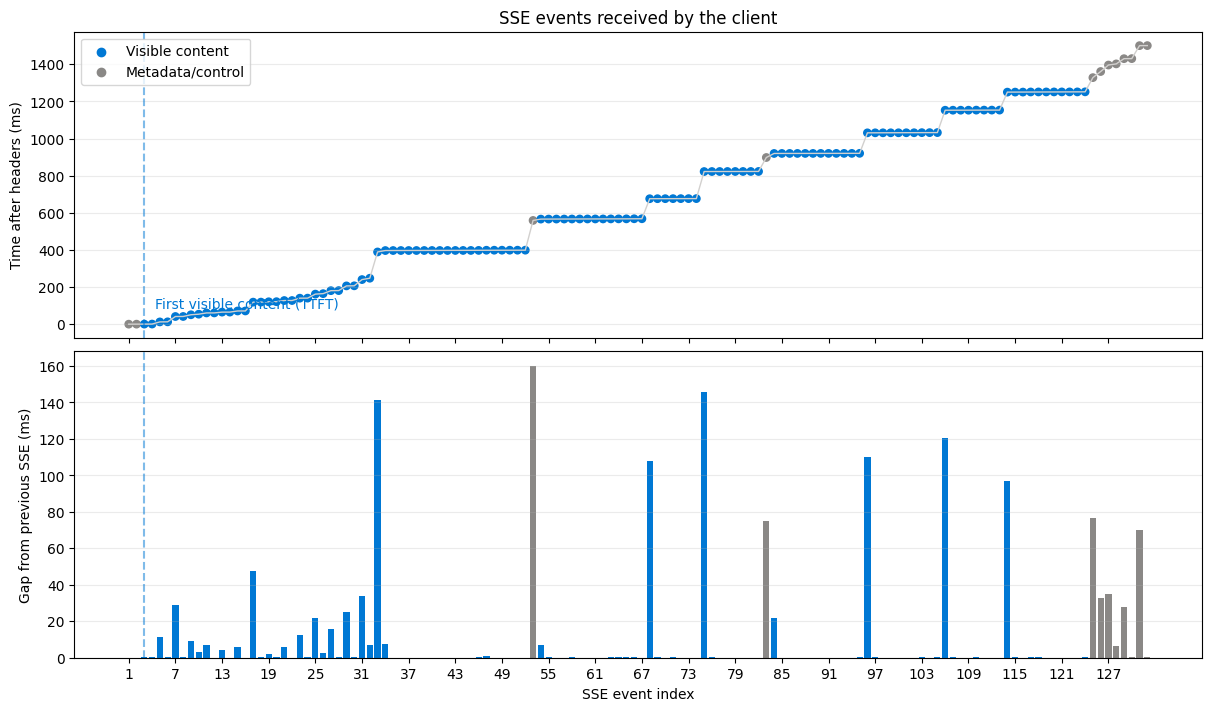

,event_index,event_type,received_from_request_start_ms,received_after_headers_ms,since_previous_sse_received_ms,visible_content,content_chunk_chars
0,1,chat.event,15714.559,0.342,NaN,False,0
1,2,chat.role.delta,15714.651,0.433,0.092,False,0
2,3,chat.content.delta,15714.910,0.692,0.259,True,2
3,4,chat.content.delta,15715.185,0.968,0.275,True,11
4,5,chat.content.delta,15726.718,12.501,11.533,True,2
...,...,...,...,...,...,...,...
127,128,chat.event,17116.042,1401.825,6.177,False,0
128,129,chat.event,17144.081,1429.863,28.038,False,0
129,130,chat.event,17144.390,1430.172,0.309,False,0
130,131,chat.event,17214.297,1500.080,69.907,False,0


Note: Azure does not emit a generated_at timestamp per token/chunk, so generation-to-receipt latency cannot be calculated client-side.


In [36]:
if event_timelines:
    timeline_df = pd.DataFrame(event_timelines[0])
    content_color = "#0078D4"
    other_color = "#8A8886"
    event_colors = timeline_df["visible_content"].map(
        {True: content_color, False: other_color}
    )

    figure, (arrival_axis, gap_axis) = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True, constrained_layout=True
    )

    arrival_axis.plot(
        timeline_df["event_index"],
        timeline_df["received_after_headers_ms"],
        color="#D2D0CE",
        linewidth=1,
    )
    arrival_axis.scatter(
        timeline_df["event_index"],
        timeline_df["received_after_headers_ms"],
        c=event_colors,
        s=28,
    )
    arrival_axis.set_title("SSE events received by the client")
    arrival_axis.set_ylabel("Time after headers (ms)")
    arrival_axis.grid(axis="y", alpha=0.25)
    arrival_axis.scatter([], [], color=content_color, label="Visible content")
    arrival_axis.scatter([], [], color=other_color, label="Metadata/control")
    arrival_axis.legend(loc="upper left")

    gap_axis.bar(
        timeline_df["event_index"],
        timeline_df["since_previous_sse_received_ms"].fillna(0),
        color=event_colors,
        width=0.8,
    )
    gap_axis.set_ylabel("Gap from previous SSE (ms)")
    gap_axis.set_xlabel("SSE event index")
    gap_axis.grid(axis="y", alpha=0.25)

    first_content = timeline_df[timeline_df["visible_content"]].head(1)
    if not first_content.empty:
        first_content_index = int(first_content.iloc[0]["event_index"])
        for axis in (arrival_axis, gap_axis):
            axis.axvline(
                first_content_index, color=content_color, linestyle="--", alpha=0.5
            )
        arrival_axis.annotate(
            "First visible content (TTFT)",
            xy=(
                first_content_index,
                first_content.iloc[0]["received_after_headers_ms"],
            ),
            xytext=(8, 12),
            textcoords="offset points",
            color=content_color,
        )

    tick_step = max(1, len(timeline_df) // 20)
    gap_axis.set_xticks(timeline_df["event_index"].iloc[::tick_step])
    plt.show()

    display(timeline_df)
    print(
        "Note: Azure does not emit a generated_at timestamp per token/chunk, "
        "so generation-to-receipt latency cannot be calculated client-side."
    )

## Cleanup

Run this cell when finished. Re-run the client cell before collecting more samples.

In [ ]:
client.close()
credential.close()
print("Client and credential closed.")